In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [2]:
julia_colors = [
    '#00A9AD',  # teal
    '#E28F41',  # orange
    '#389826',  # green
    '#9558B2',  # purple
    '#BB7DC0',  # light purple
    '#CB3C33',  # red
    '#7C7C7C',  # grey
    '#4063D8',  # blue
]
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=julia_colors)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['legend.frameon'] = False

plt.rcParams['font.size'] = 14          
plt.rcParams['axes.labelsize'] = 16     
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['axes.titlesize'] = 16

In [4]:
graph_type = 'ER'
coup_type = 'gauss'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=d)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'gaussSKscaling':
    beta_uni = np.sqrt(d) * solve_beta_critical_gauss(d=d - 1)   
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/3)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/5)
    print(f"beta_uni = {beta_uni:.6f}")


beta_uni = 0.334483


In [129]:
folder_data = f"perm/{graph_type}_{coup_type}/coal_time_{graph_type}_{coup_type}"

dfs = [pd.read_csv(f) for f in glob.glob(f'../results/{folder_data}/coal_time_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)

if graph_type in ('EA2D', 'F2D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**2))
elif graph_type in ('EA3D', 'F3D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**3))
else:
    print("betas:", sorted(df['beta'].unique()), "\nsizes:", sorted(df['N'].unique()))
df

betas: [0.33, 0.34, 0.345, 0.35, 0.355, 0.36, 0.365, 0.37] 
L: [10, 13, 15, 20, 25, 30, 40, 50, 60, 100, 120, 150, 200, 300, 500, 1000] 
sizes: [100, 169, 225, 400, 625, 900, 1600, 2500, 3600, 10000, 14400, 22500, 40000, 90000, 250000, 1000000]


,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.350,F_beta_Glauber,False,full_star,50,1000000000,30,50,2.657374e+05,1.241649e+05
1,0.350,F_beta_Glauber,False,full_star,50,1000000000,100,50,5.879970e+06,1.652631e+06
2,0.350,F_beta_Glauber,False,full_star,50,1000000000,300,50,8.108316e+07,1.508847e+07
3,0.350,F_beta_Glauber,False,full_star,50,1000000000,500,50,2.575589e+08,4.688240e+07
4,0.350,F_beta_Glauber,False,full_star,50,1000000000,1000,5,9.407959e+08,4.418030e+07
...,...,...,...,...,...,...,...,...,...,...
67,0.345,F_beta_Glauber,False,full_star,50,1000000000,1000,48,7.544772e+08,8.549972e+07
68,0.345,F_beta_Glauber,False,full_star,50,1000000000,10,50,8.414460e+03,4.270421e+03
69,0.345,F_beta_Glauber,False,full_star,50,1000000000,20,50,6.561738e+04,2.966773e+04
70,0.345,F_beta_Glauber,False,full_star,50,1000000000,60,50,1.265454e+06,4.035071e+05


# Proba of coalescence

In [6]:
max_iter_plot = 10**9
n_runs_plot = 50
if graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.31,0.32,0.33,0.331,0.336,0.34,0.35,0.36] # beta selection for plotting
    N_plot = [10**2,10**3,10**4,10**5]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['beta'].isin(beta_plot)) &
        (df['n_runs'] == n_runs_plot) & 
        (df['max_iter'] == max_iter_plot) 
    )
elif graph_type in ('ER','RR') and coup_type == 'ising':
    N_plot = [10**2,10**3,10**4,10**5]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['n_runs'] == n_runs_plot) & 
        (df['max_iter'] == max_iter_plot) 
    )
elif graph_type == 'EA2D' and coup_type == 'ising':
    N_plot = [30,100,300,1000]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['n_runs'] == n_runs_plot) & 
        (df['max_iter'] == max_iter_plot) 
    )
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_plot = [0.19, 0.2, 0.202, 0.204, 0.205] # beta selection for plotting
    N_plot = [10,20,40,60]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['beta'].isin(beta_plot)) &
        (df['n_runs'] == n_runs_plot) & 
        (df['max_iter'] == max_iter_plot) 
    )
else:
    mask = (
        (df['n_runs'] == n_runs_plot) & 
        (df['max_iter'] == max_iter_plot) 
    )
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
4,0.260,F_beta_Glauber,False,full_star,50,1000000000,100,50,1.540632e+04,4.596672e+04
5,0.260,F_beta_Glauber,False,full_star,50,1000000000,1000,50,1.382344e+07,8.058216e+07
6,0.260,F_beta_Glauber,False,full_star,50,1000000000,10000,21,1.110295e+08,1.820643e+08
7,0.260,F_beta_Glauber,False,full_star,50,1000000000,100000,0,NaN,NaN
21,0.250,F_beta_Glauber,False,full_star,50,1000000000,100,50,5.179920e+03,4.581493e+03
23,0.250,F_beta_Glauber,False,full_star,50,1000000000,1000,50,5.498487e+05,1.392019e+06
25,0.250,F_beta_Glauber,False,full_star,50,1000000000,10000,50,3.459237e+06,1.469417e+06
27,0.250,F_beta_Glauber,False,full_star,50,1000000000,100000,50,5.199994e+07,1.119225e+07
28,0.257,F_beta_Glauber,False,full_star,50,1000000000,100,50,7.687080e+03,1.009367e+04
29,0.257,F_beta_Glauber,False,full_star,50,1000000000,1000,50,1.888040e+06,8.364466e+06


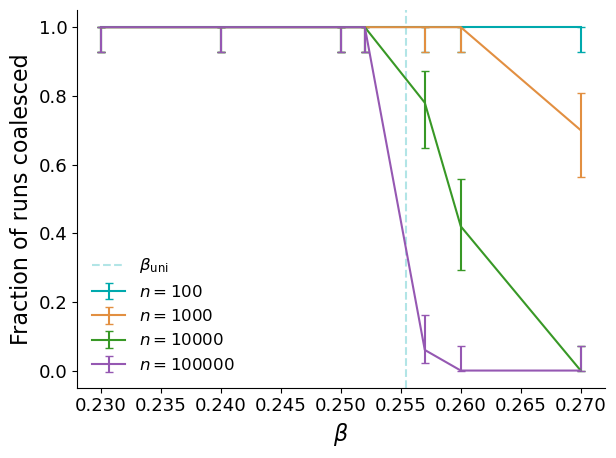

In [7]:
fig, ax = plt.subplots()

for N in sorted(df_filtered['N'].unique()):
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    if graph_type == 'EA2D' or graph_type == 'F2D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**2}$', capsize=3)
    elif graph_type == 'EA3D' or graph_type == 'F3D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**3}$', capsize=3)
    else:
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N}$', capsize=3)
ax.axvline(beta_uni, linestyle='--', alpha=0.3, label=rf'$\beta_\mathrm{{uni}}$')
ax.set_xlabel(rf'$\beta$')
ax.set_ylabel('Fraction of runs coalesced')
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
#fig.savefig(f'../results/{folder_data}/coal_frac_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')

# Scaling (log-log)

In [130]:
max_iter_plot = [10**9, 10**10]
mask = (
    (df['n_coal'] >= df['n_runs']-1) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['max_iter'].isin(max_iter_plot)) 
)
df_filtered = df[mask]

best_runs = df_filtered.groupby('beta')['n_runs'].transform('max')
df_filtered = df_filtered[df_filtered['n_runs'] == best_runs]

df_filtered = (df_filtered.sort_values('max_iter', ascending=False)
               .drop_duplicates(subset=['beta', 'N'], keep='first')
               .sort_values(['beta', 'N']))

#df_filtered

0.33 50 1000000000 [  10   20   30   60  100  200  300  500 1000]
0.34 50 1000000000 [  10   20   30   60  100  200  300  500 1000]
0.345 50 1000000000 [ 10  20  30  60 100 200 300 500]
0.35 50 1000000000 [ 10  20  30  60 100 200 300 500]
0.355 50 1000000000 [ 10  20  30  60 100 200 300 500]
0.36 50 1000000000 [ 10  13  20  30  40  60 100 120 150]
0.365 50 1000000000 [10 13 15 20 25 30 40]
0.37 50 1000000000 [10 13 15 20 25 30]


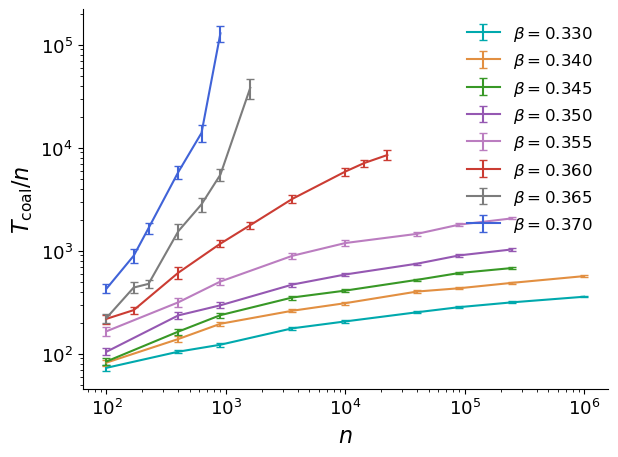

In [131]:
fig, ax = plt.subplots()

for beta in sorted(df_filtered['beta'].unique()):
    if coup_type == 'gauss' and (beta < 0.31):# or beta >= 0.35):
        continue
    if graph_type == 'EA3D' and (beta == 0.204 or beta == 0.18):
        continue
    if graph_type == 'EA2D' and beta <= 0.3:
        continue
    if graph_type == 'RR' and d==4 and beta <= 0.3:
        continue
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    n_runs_plot = sub_df['n_runs'].values       
    print(beta, n_runs_plot[0], max_iter_plot[0], N)   
    sT = sub_df['std_coal_time'].values/np.sqrt(n_runs_plot)
    if graph_type in ('EA2D', 'F2D'):
        N = N**2
    if graph_type in ('EA3D', 'F3D'):
        N = N**3
    if graph_type == 'EA4D':
        N = N**4
    ax.errorbar(N, T/N,
                yerr=sT/N,
                label=rf'$\beta={beta:.3f}$',
                capsize=3)

ax.set_xlabel(rf'$n$')
ax.set_ylabel(rf'$T_\mathrm{{coal}} / n$')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
#fig.savefig(f'../results/{folder_data}/coal_loglog_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')

# Scaling of coalescence times

In [105]:
max_iter_plot = 10**9
n_runs_plot = 50
if graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.2,0.27,0.28,0.29,0.3,0.31,0.32] # beta selection for plotting
    N_min = 50   
elif graph_type == 'ER' and coup_type == 'ising':
    beta_plot = [0.23,0.24,0.25, 0.252] # beta selection for plotting
    N_min = 50   
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_plot = [0.33,0.34,0.35,0.36] # beta selection for plotting
    N_min = 0   
elif graph_type == 'RR' and d == 4:
    beta_plot = [0.25,0.3,0.33,0.34,0.345] # beta selection for plotting
    N_min = 0   
else:
    beta_plot = df['beta'].unique()

mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['beta'].isin(beta_plot)) &
    (df['n_runs'] == n_runs_plot) & 
    (df['max_iter'] == max_iter_plot) &
    (df['N'] >= N_min)
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.130,F_beta_Glauber,False,full_star,50,1000000000,4,50,1.056864e+04,3.512050e+03
1,0.130,F_beta_Glauber,False,full_star,50,1000000000,8,50,3.383314e+05,8.017828e+04
2,0.130,F_beta_Glauber,False,full_star,50,1000000000,10,50,9.646799e+05,2.063604e+05
3,0.130,F_beta_Glauber,False,full_star,50,1000000000,15,50,5.713016e+06,8.718374e+05
4,0.130,F_beta_Glauber,False,full_star,50,1000000000,20,50,2.127829e+07,3.899727e+06
5,0.130,F_beta_Glauber,False,full_star,50,1000000000,30,50,1.213266e+08,1.405995e+07
6,0.130,F_beta_Glauber,False,full_star,50,1000000000,5,50,3.523732e+04,1.041070e+04
7,0.130,F_beta_Glauber,False,full_star,50,1000000000,6,50,8.305440e+04,2.611049e+04
8,0.130,F_beta_Glauber,False,full_star,50,1000000000,7,50,1.703628e+05,5.062323e+04
9,0.130,F_beta_Glauber,False,full_star,50,1000000000,13,50,3.080862e+06,6.562107e+05


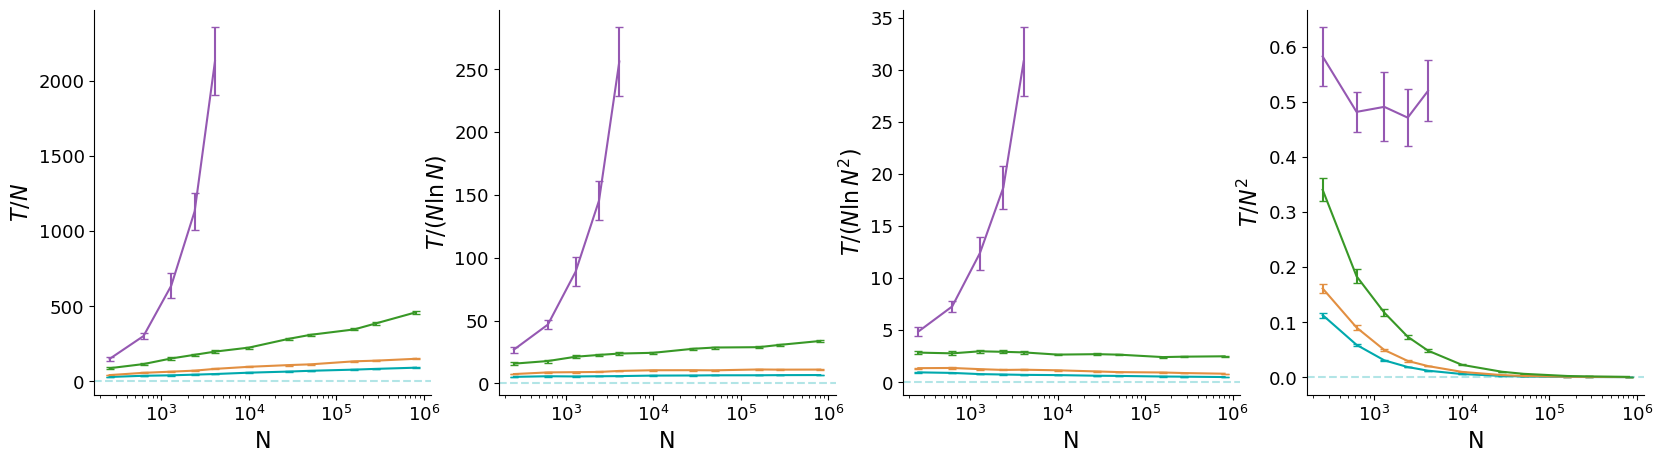

In [106]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                lambda N, T, sT: sT / N / np.sqrt(n_runs_plot)),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N) * np.sqrt(n_runs_plot))),
    r'$T / (N \ln N^2)$': (lambda N, T: T / (N * np.log(N)**2), 
                          lambda N, T, sT: sT / (N * np.log(N)**2 * np.sqrt(n_runs_plot))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2 / np.sqrt(n_runs_plot)),
}
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in sorted(df_filtered['beta'].unique()):
        if graph_type in ('ER','RR') and beta > beta_uni:
            continue
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        if graph_type in ('EA2D', 'F2D'):
            N = N**2
        if graph_type in ('EA3D', 'F3D'):
            N = N**3
        if graph_type == 'EA4D':
            N = N**4
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.set_xscale('log')   
plt.show()

beta=0.120 [NlnN]: A1=7.6523 ± 0.1450, B1=-13.8915 ± 1.2191, R²=0.9352
beta=0.120 [N**D]:  C=14.8349 ± 0.9835, D=1.1388 ± 0.0068, R²=0.9997
beta=0.120 [N(lnN)²]: A2=0.1913 ± 0.0192, B2=4.2642 ± 0.1615, R²=0.9873

beta=0.130 [NlnN]: A1=13.7248 ± 0.2793, B1=-33.6163 ± 2.3480, R²=0.9579
beta=0.130 [N**D]:  C=21.2173 ± 2.2513, D=1.1522 ± 0.0109, R²=0.9992
beta=0.130 [N(lnN)²]: A2=0.4879 ± 0.0639, B2=5.3067 ± 0.5375, R²=0.9155

beta=0.140 [NlnN]: A1=43.1951 ± 1.2218, B1=-159.0613 ± 10.2728, R²=0.9638
beta=0.140 [N**D]:  C=35.4084 ± 4.0587, D=1.1946 ± 0.0118, R²=0.9991
beta=0.140 [N(lnN)²]: A2=2.1889 ± 0.1387, B2=4.4084 ± 1.1665, R²=0.6134

beta=0.145 [NlnN]: A1=602.0708 ± 158.3861, B1=-3379.1858 ± 1082.3129, R²=0.7647
beta=0.145 [N**D]:  C=0.6847 ± 0.1828, D=1.9577 ± 0.0375, R²=0.9989
beta=0.145 [N(lnN)²]: A2=70.6698 ± 17.1991, B2=-385.8922 ± 117.5282, R²=0.7823



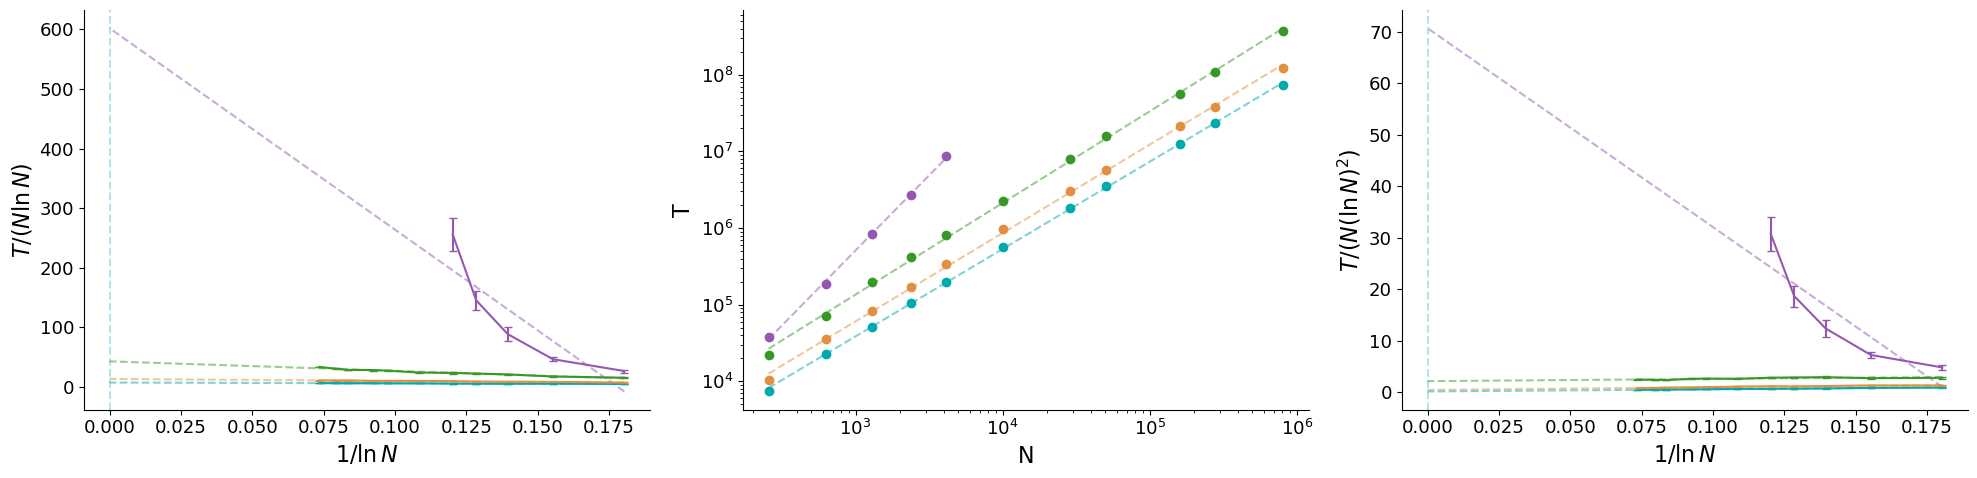

In [108]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fit_coeffs = {}

for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    if graph_type in ('EA2D', 'F2D'):
        N = N**2
    if graph_type in ('EA3D', 'F3D'):
        N = N**3
    if graph_type == 'EA4D':
        N = N**4
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values / np.sqrt(n_runs_plot)

    # --- plot 1: T/(NlnN) vs 1/lnN ---
    x = 1 / np.log(N)
    y = T / (N * np.log(N))
    yerr = sT / (N * np.log(N))
    eb = axes[0].errorbar(x, y, yerr=yerr, label=f'beta={beta:.3f}', capsize=3)
    color = eb.lines[0].get_color() # reuse same color for fit line
    res1 = linregress(x, y)  # slope=B1, intercept=A1
    x_fit = np.linspace(x.max(), 0, 100)
    axes[0].plot(x_fit, res1.slope * x_fit + res1.intercept, linestyle='--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [NlnN]: A1={res1.intercept:.4f} ± {res1.intercept_stderr:.4f}, "
          f"B1={res1.slope:.4f} ± {res1.stderr:.4f}, R²={res1.rvalue**2:.4f}")

    # --- plot 2: log T vs log N ---
    res2 = linregress(np.log(N), np.log(T))
    D = res2.slope
    C = np.exp(res2.intercept)
    C_err = C * res2.intercept_stderr
    axes[1].loglog(N, T, 'o', color=color, label=f'beta={beta:.3f} (D={D:.3f})')
    axes[1].loglog(N, C * N**D, '--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [N**D]:  C={C:.4f} ± {C_err:.4f}, "
          f"D={D:.4f} ± {res2.stderr:.4f}, R²={res2.rvalue**2:.4f}")

    # --- plot 3: T/(N(lnN)^2) vs 1/lnN ---
    y3 = T / (N * np.log(N)**2)
    yerr3 = sT / (N * np.log(N)**2)
    axes[2].errorbar(x, y3, yerr=yerr3, capsize=3, color=color, label=f'beta={beta:.3f}')
    res3 = linregress(x, y3)  # intercept=A2, slope=B2
    axes[2].plot(x_fit, res3.slope * x_fit + res3.intercept, linestyle='--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [N(lnN)²]: A2={res3.intercept:.4f} ± {res3.intercept_stderr:.4f}, "
        f"B2={res3.slope:.4f} ± {res3.stderr:.4f}, R²={res3.rvalue**2:.4f}\n")

    fit_coeffs[beta] = {
        # NlnN fit 
        'A1': res1.intercept, 'A1_err': res1.intercept_stderr,
        'B1': res1.slope,     'B1_err': res1.stderr,
        'r2_NlnN': res1.rvalue**2,
        # power law fit
        'C': C,               'C_err': C_err,
        'D': D,               'D_err': res2.stderr,
        'r2_powerlaw': res2.rvalue**2,
        'A2': res3.intercept, 'A2_err': res3.intercept_stderr,
        'B2': res3.slope,     'B2_err': res3.stderr,
        'r2_NlnN2': res3.rvalue**2,
    }

axes[0].axvline(0, linestyle='--', alpha=0.3)
axes[0].set_xlabel(r'$1 / \ln N$')
axes[0].set_ylabel(r'$T / (N \ln N)$')

axes[1].set_xlabel('N')
axes[1].set_ylabel('T')

axes[2].axvline(0, linestyle='--', alpha=0.3)
axes[2].set_xlabel(r'$1 / \ln N$')
axes[2].set_ylabel(r'$T / (N (\ln N)^2)$')

plt.tight_layout()
plt.show()

beta_sel_list= [0.12, 0.13]


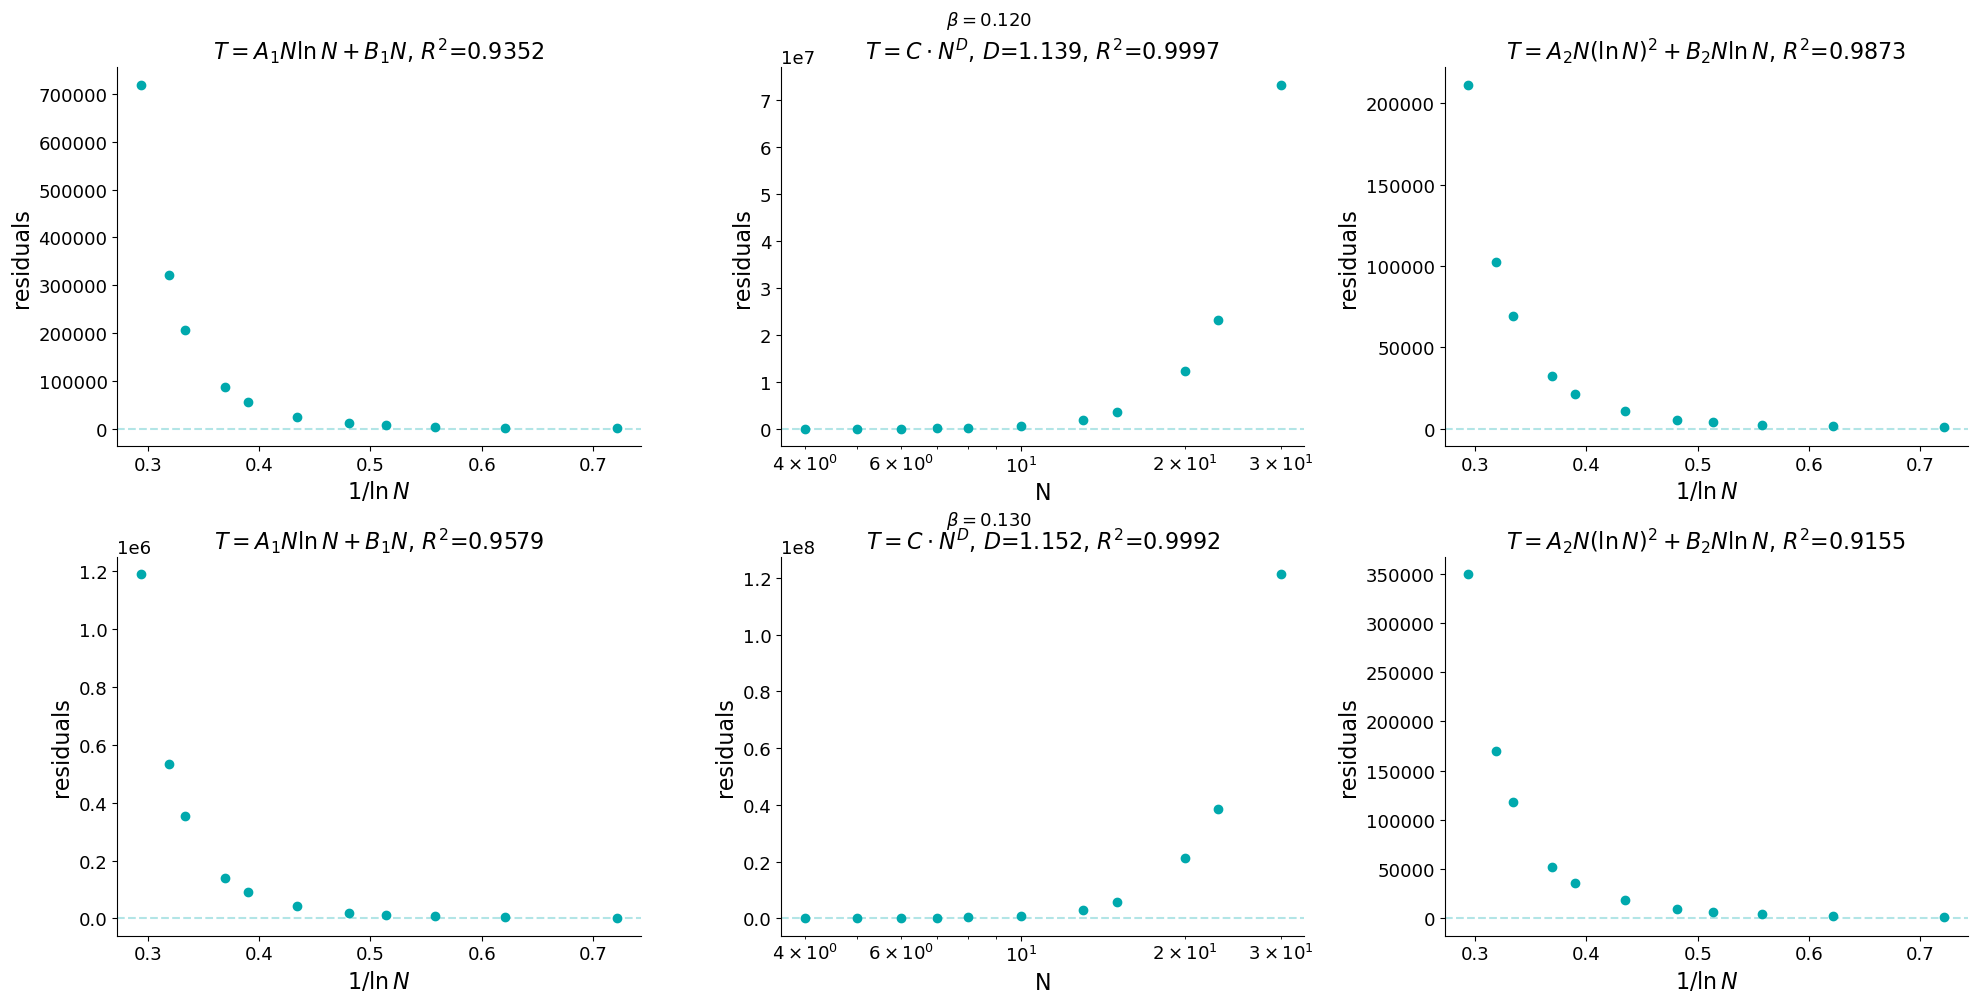

In [109]:
if graph_type == 'ER' and coup_type == 'gauss':
    beta_sel_list = [0.29, 0.31]
elif graph_type == 'ER' and coup_type == 'ising':
    beta_sel_list = [0.23,0.24]
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_sel_list = [0.33,0.34]
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_sel_list = [0.18,0.19]
elif graph_type == 'EA4D' and coup_type == 'ising':
    beta_sel_list = [0.12,0.13]
elif graph_type == 'RR' and d == 4:
    beta_sel_list = [0.33,0.34]
elif graph_type == 'RR' and d == 5:
    beta_sel_list = [0.23,0.24]
elif graph_type == 'RR' and d == 6:
    beta_sel_list = [0.19,0.2]
elif graph_type == 'RR' and d == 8:
    beta_sel_list = [0.12,0.13]
else:
    beta_sel_list = [df['beta'].unique()[0]]

print("beta_sel_list=", beta_sel_list)

n_beta = len(beta_sel_list)
fig, axes = plt.subplots(n_beta, 3, figsize=(20, 5 * n_beta), squeeze=False)

for row, beta_sel in enumerate(beta_sel_list):
    sub_df = df_filtered[df_filtered['beta'] == beta_sel].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values

    x = 1 / np.log(N)
    y = T / (N * np.log(N))

    fc = fit_coeffs[beta_sel]

    ax0, ax1, ax2 = axes[row]

    # --- residuals of NlnN fit ---
    y_pred1 = fc['A1'] + fc['B1'] * x
    residuals1 = y - y_pred1
    ax0.axhline(0, linestyle='--', alpha=0.3)
    ax0.plot(x, residuals1, 'o')
    ax0.set_xlabel(r'$1 / \ln N$')
    ax0.set_ylabel('residuals')
    ax0.set_title(rf"$T = A_1 N\ln N + B_1 N$, $R^2$={fc['r2_NlnN']:.4f}")

    # --- residuals of power law fit ---
    y_pred2 = fc['C'] * N**fc['D']
    residuals2 = T - y_pred2
    ax1.axhline(0, linestyle='--', alpha=0.3)
    ax1.plot(N, residuals2, 'o')
    ax1.set_xscale('log')
    ax1.set_xlabel('N')
    ax1.set_ylabel('residuals')
    ax1.set_title(rf"$T = C \cdot N^D$, $D$={fc['D']:.3f}, $R^2$={fc['r2_powerlaw']:.4f}")

    # --- residuals of N(lnN)^2 fit ---
    y3 = T / (N * np.log(N)**2)
    y_pred3 = fc['A2'] + fc['B2'] * x
    residuals3 = y3 - y_pred3
    ax2.axhline(0, linestyle='--', alpha=0.3)
    ax2.plot(x, residuals3, 'o')
    ax2.set_xlabel(r'$1 / \ln N$')
    ax2.set_ylabel('residuals')
    ax2.set_title(rf"$T = A_2 N(\ln N)^2 + B_2 N\ln N$, $R^2$={fc['r2_NlnN2']:.4f}")

    fig.text(0.5, 1 - (row + 0.02) / n_beta, rf'$\beta={beta_sel:.3f}$',
              ha='center', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

In [110]:
for beta_sel in beta_sel_list:
    sub_df = df_filtered[df_filtered['beta'] == beta_sel].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values

    fc = fit_coeffs[beta_sel]

    # R² of power law fit in linear space (comparable to NlnN R²)
    y_pred_linear = fc['C'] * N**fc['D']
    ss_res = np.sum((T - y_pred_linear)**2)
    ss_tot = np.sum((T - np.mean(T))**2)
    r2_powerlaw_linear = 1 - ss_res / ss_tot
    print(f"beta={beta_sel:.3f}: Power law R² in linear space: {r2_powerlaw_linear:.4f}")

beta=0.120: Power law R² in linear space: -0.2475
beta=0.130: Power law R² in linear space: -0.2493


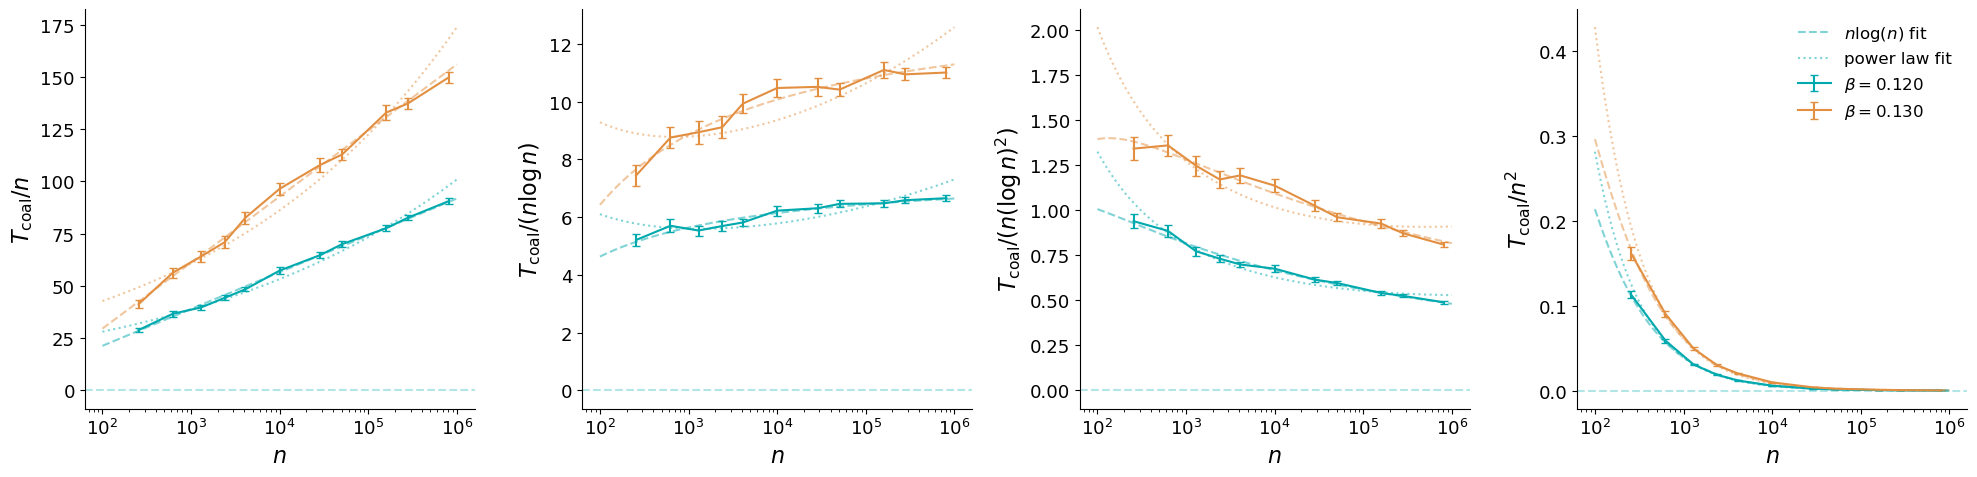

In [111]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    rf'$T_\mathrm{{coal}} / n$': (lambda N, T: T / N,
                 lambda N, T, sT: sT / N),
    rf'$T_\mathrm{{coal}} / (n \log n)$': (lambda N, T: T / (N * np.log(N)),
                                           lambda N, T, sT: sT / (N * np.log(N))),
    rf'$T_\mathrm{{coal}} / (n (\log n)^2)$': (lambda N, T: T / (N * np.log(N)**2),
                                               lambda N, T, sT: sT / (N * np.log(N)**2)),
    rf'$T_\mathrm{{coal}} / n^2$': (lambda N, T: T / N**2,
                   lambda N, T, sT: sT / N**2),
}

N_fit = np.logspace(np.log10(100), np.log10(1e6), 300)  # smooth curve for fit
prop_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for i, beta in enumerate(beta_sel_list):
        color = prop_cycle[i % len(prop_cycle)]

        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        if graph_type in ('EA2D', 'F2D'):
            N = N**2
        if graph_type in ('EA3D', 'F3D'):
            N = N**3
        if graph_type == 'EA4D':
            N = N**4
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values / np.sqrt(n_runs_plot)

        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    color=color, label=rf'$\beta={beta:.3f}$', capsize=3)

        fc = fit_coeffs[beta]

        # NlnN fit: T = A1*N*lnN + B1*N, plot through each scaling
        T_NlnN = fc['A1'] * N_fit * np.log(N_fit) + fc['B1'] * N_fit
        ax.plot(N_fit, scaling_fn(N_fit, T_NlnN), '--', color=color, alpha=0.5, label=r'$n\log(n)$ fit' if i == 0 else '')

        # power law fit: T = C * N**D
        T_power = fc['C'] * N_fit**fc['D']
        ax.plot(N_fit, scaling_fn(N_fit, T_power), ':', color=color, alpha=0.5, label='power law fit' if i == 0 else '')

        # N(lnN)^2 fit: T = A2*N*(lnN)^2 + B2*N*lnN
        T_NlnN2 = fc['A2'] * N_fit * np.log(N_fit)**2 + fc['B2'] * N_fit * np.log(N_fit)
        #ax.plot(N_fit, scaling_fn(N_fit, T_NlnN2), '-.', color=color, alpha=0.5, label=r'$n(\ln n)^2$ fit')

    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel(r'$n$')
    ax.set_ylabel(label)
    ax.set_xscale('log')

axes[3].legend()
plt.tight_layout()
plt.show()

In [112]:
if len(beta_sel_list)>1:
    fig.savefig(f'../results/{folder_data}/coal_scaling_{graph_type}_{coup_type}_d{d}_beta{beta_sel_list[0]:.3f}_{beta_sel_list[len(beta_sel_list)-1]:.3f}.pdf', bbox_inches='tight')
else:
    fig.savefig(f'../results/{folder_data}/coal_scaling_{graph_type}_{coup_type}_d{d}_beta{beta_sel_list:.3f}.pdf', bbox_inches='tight')
